In [1]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
import itertools
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Pengumpulan Data
df = pd.read_csv('WHR2024.csv')
print(f"Shape dataset : {df.shape}")
print(f"Jumlah negara : {df.shape[0]}")
print(f"Jumlah kolom  : {df.shape[1]}")
print("\n5 Data Pertama:")
df.head()

Shape dataset : (143, 11)
Jumlah negara : 143
Jumlah kolom  : 11

5 Data Pertama:


,Country name,Ladder score,upperwhisker,lowerwhisker,Log GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Dystopia + residual
0,Finland,7.741,7.815,7.667,1.844,1.572,0.695,0.859,0.142,0.546,2.082
1,Denmark,7.583,7.665,7.500,1.908,1.520,0.699,0.823,0.204,0.548,1.881
2,Iceland,7.525,7.618,7.433,1.881,1.617,0.718,0.819,0.258,0.182,2.050
3,Sweden,7.344,7.422,7.267,1.878,1.501,0.724,0.838,0.221,0.524,1.658
4,Israel,7.341,7.405,7.277,1.803,1.513,0.740,0.641,0.153,0.193,2.298


In [3]:
# Pemilihan Fitur & Preprocessing
features = [
    'Log GDP per capita', 
    'Social support', 
    'Healthy life expectancy', 
    'Freedom to make life choices', 
    'Generosity', 
    'Perceptions of corruption'
]

# Cek missing values sebelum cleaning
print("Missing values sebelum cleaning:")
print(df[features].isnull().sum())

# Drop baris dengan missing value
df = df.dropna(subset=features).reset_index(drop=True)
X = df[features]

Missing values sebelum cleaning:
Log GDP per capita              3
Social support                  3
Healthy life expectancy         3
Freedom to make life choices    3
Generosity                      3
Perceptions of corruption       3
dtype: int64


In [4]:
# Preprocessing (Standardization/ StandardScaler)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"\n✅ Data setelah cleaning: {df.shape[0]} negara")
print(f"✅ Fitur yang digunakan: {features}")

# Statistik Deskriptif
print("\nStatistik Deskriptif:")
df[features].describe().round(4)


✅ Data setelah cleaning: 140 negara
✅ Fitur yang digunakan: ['Log GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption']

Statistik Deskriptif:


,Log GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
count,140.0000,140.0000,140.0000,140.0000,140.0000,140.0000
mean,1.3788,1.1343,0.5209,0.6206,0.1463,0.1541
std,0.4251,0.3333,0.1649,0.1625,0.0734,0.1262
min,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,1.0778,0.9218,0.3980,0.5275,0.0910,0.0688
50%,1.4315,1.2375,0.5495,0.6410,0.1365,0.1205
75%,1.7415,1.3832,0.6485,0.7360,0.1925,0.1938
max,2.1410,1.6170,0.8570,0.8630,0.4010,0.5750


In [5]:
# Implementasi Algoritma DBSCAN
# Tuning parameter Epsilon dan MinPts
best_sil = -1
best_eps = 0.5
best_min_samples = 3
results_dbscan = []

# Grid Search (Mencoba kombinasi eps dari 0.5 s/d 2.0, min_samples 3 s/d 10)
for eps, ms in itertools.product(np.arange(0.5, 2.1, 0.1), range(3, 11)):
    db_temp = DBSCAN(eps=round(eps, 1), min_samples=ms)
    labels = db_temp.fit_predict(X_scaled)
    
    # Syarat: Harus lebih dari 1 cluster valid (selain noise)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise    = list(labels).count(-1)
    
    if n_clusters >= 2:
        sil = silhouette_score(X_scaled, labels)
        results_dbscan.append({'eps': round(eps,1), 'min_samples': ms,
                               'n_clusters': n_clusters, 'n_noise': n_noise,
                               'silhouette': round(sil, 4)})
        if sil > best_sil:
            best_sil = sil
            best_eps = round(eps, 1)
            best_min_samples = ms

print(f"DBSCAN Parameter Optimal: Epsilon (ε) = {best_eps}, MinPts = {best_min_samples}, Silhouette: {best_sil:.4f}")

# Fit DBSCAN Terbaik
dbscan_best = DBSCAN(eps=best_eps, min_samples=best_min_samples)
df['Cluster_DBSCAN'] = dbscan_best.fit_predict(X_scaled)

n_clusters_db = len(set(df['Cluster_DBSCAN'])) - (1 if -1 in df['Cluster_DBSCAN'].values else 0)
n_noise_db    = (df['Cluster_DBSCAN'] == -1).sum()
print(f"\nHasil DBSCAN:")
print(f"Jumlah Cluster : {n_clusters_db}")
print(f"Jumlah Noise   : {n_noise_db} negara")
print("\nDistribusi cluster:")
print(df['Cluster_DBSCAN'].value_counts())

DBSCAN Parameter Optimal: Epsilon (ε) = 1.3, MinPts = 6, Silhouette: 0.2466

Hasil DBSCAN:
Jumlah Cluster : 2
Jumlah Noise   : 29 negara

Distribusi cluster:
Cluster_DBSCAN
 0    89
-1    29
 1    22
Name: count, dtype: int64


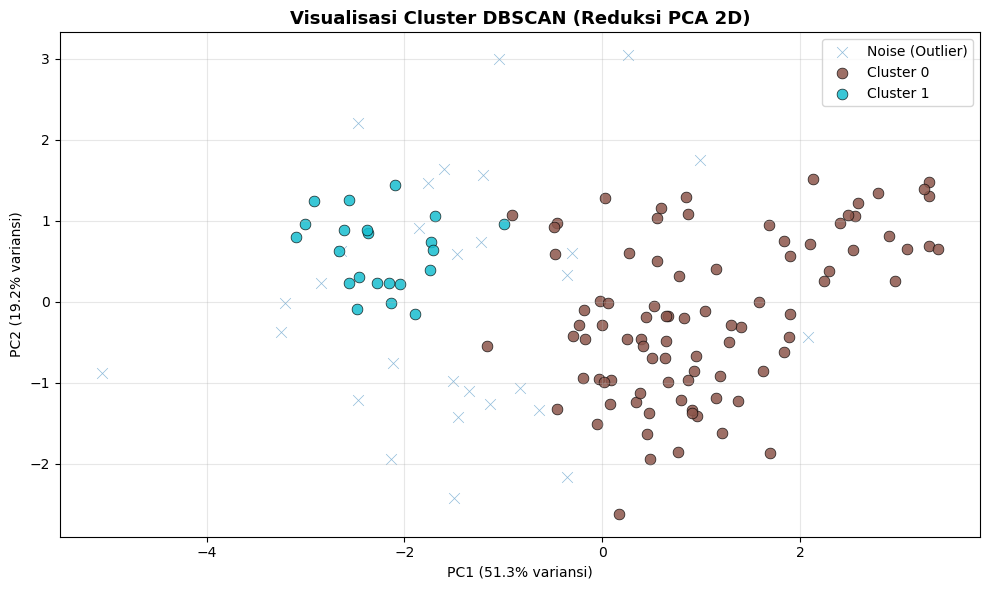


 Plot DBSCAN disimpan sebagai 'plot_dbscan_cluster.png'


In [6]:
# Visualisasi Hasil DBSCAN (PCA 2D)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(10, 6))
unique_labels = sorted(df['Cluster_DBSCAN'].unique())
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

for label, color in zip(unique_labels, colors):
    mask = df['Cluster_DBSCAN'] == label
    label_name = f'Noise (Outlier)' if label == -1 else f'Cluster {label}'
    marker = 'x' if label == -1 else 'o'
    alpha  = 0.5 if label == -1 else 0.85
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=[color], label=label_name, marker=marker,
               s=60, alpha=alpha, edgecolors='k' if label != -1 else 'none', linewidths=0.5)

ax.set_title('Visualisasi Cluster DBSCAN (Reduksi PCA 2D)', fontsize=13, fontweight='bold')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variansi)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variansi)')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('plot_dbscan_cluster.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"\n Plot DBSCAN disimpan sebagai 'plot_dbscan_cluster.png'")

GMM Optimal (berdasarkan BIC): n_components = 2


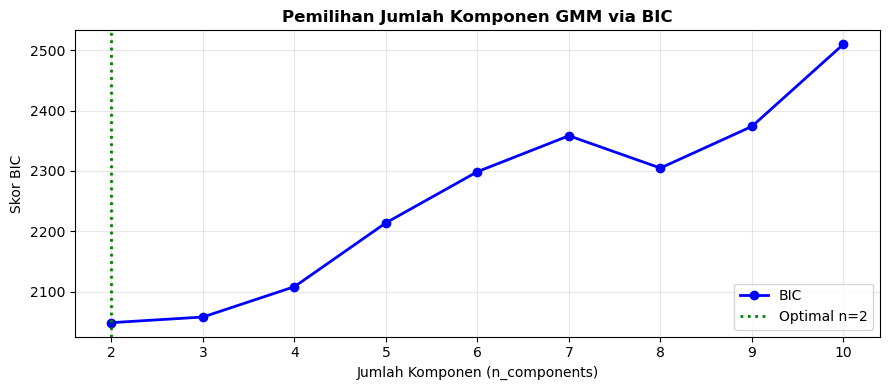

Plot BIC disimpan


In [7]:
# Implementasi Algoritma Gaussian Mixture Model
# Mencari jumlah komponen optimal (best_n) menggunakan BIC (Bayesian Information Criterion)
bic_scores = []
n_components_range = range(2, 11)

for n in n_components_range:
    gmm_temp = GaussianMixture(n_components=n, covariance_type='full', random_state=42)
    gmm_temp.fit(X_scaled)
    bic_scores.append(gmm_temp.bic(X_scaled))

best_n = n_components_range[np.argmin(bic_scores)]
print(f"GMM Optimal (berdasarkan BIC): n_components = {best_n}")

# Plot BIC
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(n_components_range, bic_scores, 'bo-', label='BIC', linewidth=2)
ax.axvline(x=best_n, color='green', linestyle=':', linewidth=2, label=f'Optimal n={best_n}')
ax.set_xlabel('Jumlah Komponen (n_components)')
ax.set_ylabel('Skor BIC')
ax.set_title('Pemilihan Jumlah Komponen GMM via BIC', fontsize=12, fontweight='bold')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('plot_gmm_bic.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot BIC disimpan")

In [8]:
# Fit GMM Terbaik & Visualisasi
# Catatan Metodologi:
# BIC optimal = 2 komponen untuk data multidimensi.
# Untuk keperluan interpretasi dan perbandingan yang setara dengan DBSCAN
# (yang menghasilkan 2 cluster valid + noise), model GMM menggunakan n=best_n.
gmm_best = GaussianMixture(n_components=best_n, covariance_type='full', random_state=42)
gmm_best.fit(X_scaled)
df['Cluster_GMM'] = gmm_best.predict(X_scaled)
df['GMM_Prob_Max']  = gmm_best.predict_proba(X_scaled).max(axis=1)

print(f"GMM Cluster (n={best_n}):")
print(df['Cluster_GMM'].value_counts())
print(f"\nRata-rata probabilitas keanggotaan: {df['GMM_Prob_Max'].mean():.4f}")

GMM Cluster (n=2):
Cluster_GMM
0    75
1    65
Name: count, dtype: int64

Rata-rata probabilitas keanggotaan: 0.9480


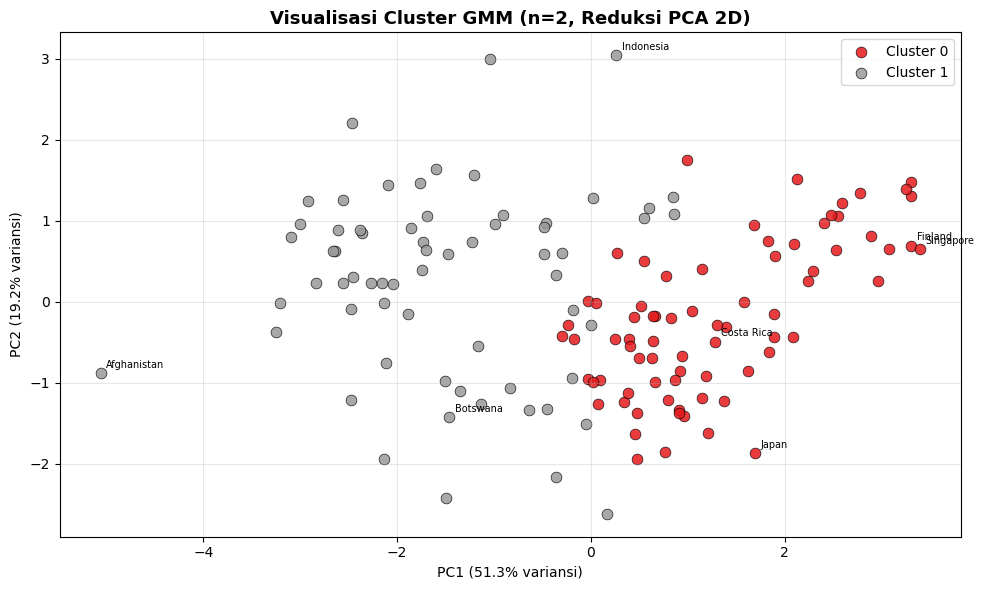

Plot GMM disimpan


In [9]:
# Visualisasi GMM PCA
fig, ax = plt.subplots(figsize=(10, 6))
colors_gmm = plt.cm.Set1(np.linspace(0, 1, best_n))

for label, color in enumerate(colors_gmm):
    mask = df['Cluster_GMM'] == label
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=[color], label=f'Cluster {label}',
               s=60, alpha=0.85, edgecolors='k', linewidths=0.5)

for idx, row in df.iterrows():
    if row['Country name'] in ['Finland', 'Afghanistan', 'Indonesia', 'Japan',
                                'Costa Rica', 'Singapore', 'Botswana']:
        ax.annotate(row['Country name'], (X_pca[idx, 0], X_pca[idx, 1]),
                    fontsize=7, xytext=(4, 4), textcoords='offset points')

ax.set_title(f'Visualisasi Cluster GMM (n={best_n}, Reduksi PCA 2D)', fontsize=13, fontweight='bold')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variansi)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variansi)')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('plot_gmm_cluster.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot GMM disimpan")

In [10]:
# Evaluasi Model (Silhouette Score, Davies Bouldin Index, Calinski-Harabasz Index)
def evaluate_model(X, labels, model_name):
    n_valid_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    if n_valid_clusters < 2:
        print(f"{model_name}: Tidak cukup cluster untuk evaluasi.")
        return None, None, None
    
    # Untuk DBSCAN: exclude noise dari evaluasi internal
    mask = labels != -1
    X_eval = X[mask]
    labels_eval = labels[mask]
    
    s_score  = silhouette_score(X_eval, labels_eval)
    db_index = davies_bouldin_score(X_eval, labels_eval)
    ch_index = calinski_harabasz_score(X_eval, labels_eval)
    return s_score, db_index, ch_index

s_db, db_db, ch_db = evaluate_model(X_scaled, df['Cluster_DBSCAN'].values, "DBSCAN")
s_gm, db_gm, ch_gm = evaluate_model(X_scaled, df['Cluster_GMM'].values, "GMM")
print(f"{'Metrik Evaluasi':<28} {'DBSCAN':>10} {'GMM':>12}")
print("=" * 55)
print(f"{'Silhouette Score':<28} {s_db:>10.4f} {s_gm:>12.4f}")
print(f"{'Davies-Bouldin Index':<28} {db_db:>10.4f} {db_gm:>12.4f}")
print(f"{'Calinski-Harabasz Index ':<28} {ch_db:>10.4f} {ch_gm:>12.4f}")

Metrik Evaluasi                  DBSCAN          GMM
Silhouette Score                 0.3968       0.2911
Davies-Bouldin Index             0.8246       1.3447
Calinski-Harabasz Index         66.2104      67.3668


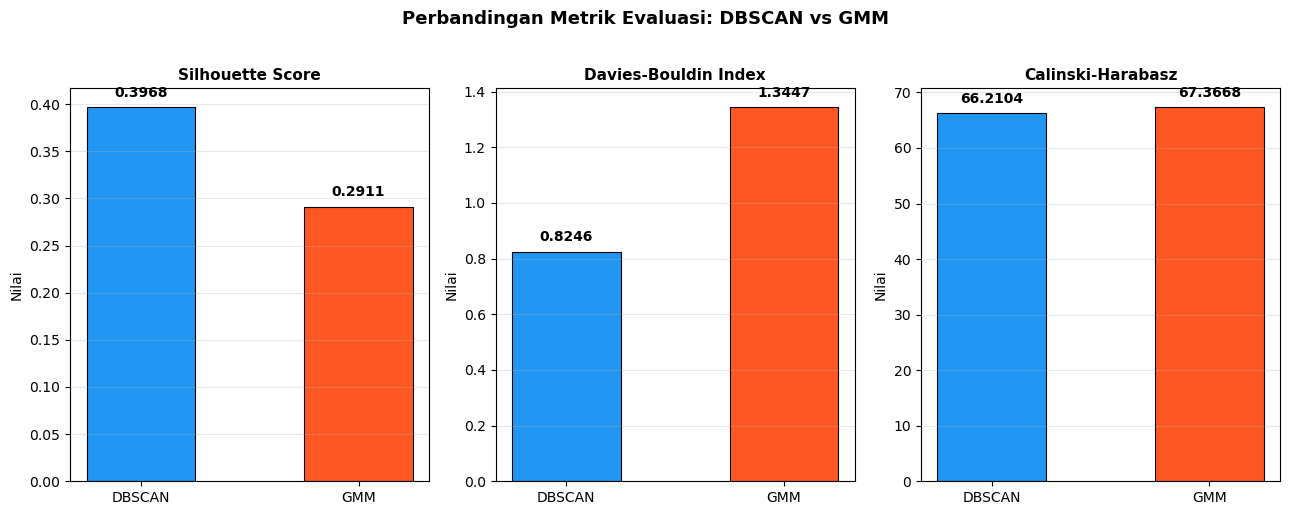


 Plot evaluasi perbandingan disimpan


In [11]:
# Bar chart perbandingan
fig, axes = plt.subplots(1, 3, figsize=(13, 5))
metrics   = ['Silhouette Score', 'Davies-Bouldin Index', 'Calinski-Harabasz']
db_vals   = [s_db, db_db, ch_db]
gm_vals   = [s_gm, db_gm, ch_gm]
colors_   = [['#2196F3','#FF5722'], ['#2196F3','#FF5722'], ['#2196F3','#FF5722']]

for i, (ax, metric, dv, gv) in enumerate(zip(axes, metrics, db_vals, gm_vals)):
    bars = ax.bar(['DBSCAN', 'GMM'], [dv, gv], color=['#2196F3','#FF5722'],
                  edgecolor='black', linewidth=0.8, width=0.5)
    for bar, val in zip(bars, [dv, gv]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(dv,gv)*0.02,
                f'{val:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.set_title(metric, fontsize=11, fontweight='bold')
    ax.set_ylabel('Nilai')
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Perbandingan Metrik Evaluasi: DBSCAN vs GMM', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('plot_evaluasi_perbandingan.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n Plot evaluasi perbandingan disimpan")

In [12]:
# Profil Cluster DBSCAN
print("Profil Cluster DBSCAN")
dbscan_profile = df[df['Cluster_DBSCAN'] != -1].groupby('Cluster_DBSCAN')[
    features + ['Ladder score']].mean().round(3)
print(dbscan_profile)

print("\nProfil Cluster GMM")
gmm_profile = df.groupby('Cluster_GMM')[
    features + ['Ladder score']].mean().round(3)
print(gmm_profile)

# Perbandingan penempatan negara
print("\n Negara yang Berbeda Cluster")
df['Konsisten'] = df.apply(
    lambda row: 'Konsisten' if 
    (row['Cluster_DBSCAN'] != -1 and 
     str(row['Cluster_DBSCAN']) == str(row['Cluster_GMM']))
    else 'Berbeda', axis=1)
berbeda = df[df['Konsisten'] == 'Berbeda'][
    ['Country name','Cluster_DBSCAN','Cluster_GMM','Ladder score']]
print(berbeda.to_string(index=False))

Profil Cluster DBSCAN
                Log GDP per capita  Social support  Healthy life expectancy  \
Cluster_DBSCAN                                                                
0                            1.608           1.311                    0.614   
1                            0.826           0.705                    0.292   

                Freedom to make life choices  Generosity  \
Cluster_DBSCAN                                             
0                                      0.692       0.141   
1                                      0.550       0.157   

                Perceptions of corruption  Ladder score  
Cluster_DBSCAN                                           
0                                   0.176         6.189  
1                                   0.111         4.357  

Profil Cluster GMM
             Log GDP per capita  Social support  Healthy life expectancy  \
Cluster_GMM                                                                
0               

In [13]:
# Kategorisasi GMM Univariat
# ============================================================
# Menggunakan GMM univariat (1D) dengan n_components=3 untuk setiap variabel. Ini valid karena tiap variabel dianalisis independen.
# DBSCAN tidak cocok untuk univariat 1D → diganti GMM untuk konsistensi.

def kategorisasi_gmm_univariat(df_in, kolom, label_rendah, label_sedang, label_tinggi, n=3):
    """Kategorisasi satu variabel menggunakan GMM univariat (n=3 komponen)."""
    sc = StandardScaler()
    X_1d = sc.fit_transform(df_in[[kolom]])
    gmm = GaussianMixture(n_components=n, covariance_type='full', random_state=42)
    gmm.fit(X_1d)
    labels = gmm.predict(X_1d)
    
    # Urutkan cluster berdasarkan mean nilai asli
    means = df_in.groupby(labels)[kolom].mean().sort_values()
    idx_sorted = means.index.tolist()
    
    if n == 3:
        mapping = {idx_sorted[0]: label_rendah,
                   idx_sorted[1]: label_sedang,
                   idx_sorted[2]: label_tinggi}
    elif n == 2:
        mapping = {idx_sorted[0]: label_rendah,
                   idx_sorted[1]: label_tinggi}
    
    return pd.Series(labels).map(mapping).values

# Jalankan kategorisasi semua variabel 
df['GDP_Kategori'] = kategorisasi_gmm_univariat(df, 'Log GDP per capita', 'Miskin', 'Menengah', 'Kaya')
df['Sosial_Kategori'] = kategorisasi_gmm_univariat(df, 'Social support', 'Dukungan Sosial Rendah', 'Dukungan Sosial Sedang', 'Dukungan Sosial Tinggi')
df['Healthy_Kategori'] = kategorisasi_gmm_univariat(df, 'Healthy life expectancy', 'Harapan Hidup Rendah', 'Harapan Hidup Sedang', 'Harapan Hidup Tinggi')
df['Freedom_Kategori'] = kategorisasi_gmm_univariat(df, 'Freedom to make life choices', 'Kebebasan Rendah', 'Kebebasan Sedang', 'Kebebasan Tinggi')
df['Generosity_Kategori'] = kategorisasi_gmm_univariat(df, 'Generosity', 'Kurang Dermawan', 'Netral', 'Dermawan')
df['Corruption_Kategori'] = kategorisasi_gmm_univariat(df, 'Perceptions of corruption', 'Tinggi Korupsi', 'Korupsi Sedang', 'Rendah Korupsi')

# Verifikasi distribusi
for col in ['GDP_Kategori','Sosial_Kategori','Healthy_Kategori','Freedom_Kategori','Generosity_Kategori','Corruption_Kategori']:
    print(f"\n{col}:")
    print(df[col].value_counts().to_string())

print("\n Semua kategori berhasil dibuat dengan GMM Univariat!")


GDP_Kategori:
GDP_Kategori
Kaya        51
Menengah    49
Miskin      40

Sosial_Kategori:
Sosial_Kategori
Dukungan Sosial Tinggi    76
Dukungan Sosial Sedang    40
Dukungan Sosial Rendah    24

Healthy_Kategori:
Healthy_Kategori
Harapan Hidup Sedang    51
Harapan Hidup Tinggi    45
Harapan Hidup Rendah    44

Freedom_Kategori:
Freedom_Kategori
Kebebasan Sedang    69
Kebebasan Tinggi    59
Kebebasan Rendah    12

Generosity_Kategori:
Generosity_Kategori
Netral             63
Kurang Dermawan    52
Dermawan           25

Corruption_Kategori:
Corruption_Kategori
Tinggi Korupsi    79
Korupsi Sedang    42
Rendah Korupsi    19

 Semua kategori berhasil dibuat dengan GMM Univariat!


In [14]:
# Analisis Anomali — Miskin tapi Senang & Kaya tapi Sedih
median_ladder = df['Ladder score'].median()
print(f"Median Ladder Score (ambang kebahagiaan) : {median_ladder:.3f}")

# Anomali GDP vs Kebahagiaan
df['Anomali_GDP'] = 'Normal'
df.loc[(df['GDP_Kategori'] == 'Miskin') & (df['Ladder score'] > median_ladder), 'Anomali_GDP'] = 'Miskin tapi Senang'
df.loc[(df['GDP_Kategori'] == 'Kaya')   & (df['Ladder score'] < median_ladder), 'Anomali_GDP'] = 'Kaya tapi Sedih'

# Anomali Korupsi vs Kebahagiaan
df['Anomali_Korupsi'] = 'Normal'
df.loc[(df['Corruption_Kategori'] == 'Tinggi Korupsi') & (df['Ladder score'] > median_ladder), 'Anomali_Korupsi'] = 'Korupsi Tinggi tapi Bahagia'
df.loc[(df['Corruption_Kategori'] == 'Rendah Korupsi') & (df['Ladder score'] < median_ladder), 'Anomali_Korupsi'] = 'Bersih tapi Tidak Bahagia'

# Anomali Generosity vs GDP
df['Anomali_Generosity'] = 'Normal'
df.loc[(df['GDP_Kategori'] == 'Miskin') & (df['Generosity_Kategori'] == 'Dermawan'), 'Anomali_Generosity'] = 'Miskin tapi Dermawan'
df.loc[(df['GDP_Kategori'] == 'Kaya')   & (df['Generosity_Kategori'] == 'Kurang Dermawan'), 'Anomali_Generosity'] = 'Kaya tapi Pelit'

print("\n Anomali 1: GDP vs Kebahagiaan")
for tipe in ['Miskin tapi Senang', 'Kaya tapi Sedih']:
    sub = df[df['Anomali_GDP'] == tipe].sort_values('Ladder score', ascending=(tipe=='Kaya tapi Sedih'))
    print(f"\n {tipe} ({len(sub)} negara):")
    print(sub[['Country name', 'Ladder score', 'Log GDP per capita']].head(10).to_string(index=False))

print("\n Anomali 2: Korupsi vs Kebahagiaan")
for tipe in ['Korupsi Tinggi tapi Bahagia', 'Bersih tapi Tidak Bahagia']:
    sub = df[df['Anomali_Korupsi'] == tipe]
    print(f"\n {tipe} ({len(sub)} negara):")
    print(sub[['Country name', 'Ladder score', 'Perceptions of corruption']].head(8).to_string(index=False))

print("\n Anomali 3: Generosity vs GDP")
for tipe in ['Miskin tapi Dermawan', 'Kaya tapi Pelit']:
    sub = df[df['Anomali_Generosity'] == tipe]
    print(f"\n {tipe} ({len(sub)} negara):")
    print(sub[['Country name', 'Generosity', 'Log GDP per capita']].head(8).to_string(index=False))

Median Ladder Score (ambang kebahagiaan) : 5.800

 Anomali 1: GDP vs Kebahagiaan

 Miskin tapi Senang (2 negara):
Country name  Ladder score  Log GDP per capita
   Nicaragua         6.284               1.097
    Honduras         5.968               1.091

 Kaya tapi Sedih (4 negara):
             Country name  Ladder score  Log GDP per capita
                  Turkiye         4.975               1.702
Hong Kong S.A.R. of China         5.316               1.909
                 Bulgaria         5.463               1.629
                   Russia         5.785               1.642

 Anomali 2: Korupsi vs Kebahagiaan

 Korupsi Tinggi tapi Bahagia (31 negara):
Country name  Ladder score  Perceptions of corruption
  Costa Rica         6.955                      0.123
     Czechia         6.822                      0.068
   Lithuania         6.818                      0.116
    Slovenia         6.743                      0.131
      Mexico         6.678                      0.127
      Kosovo

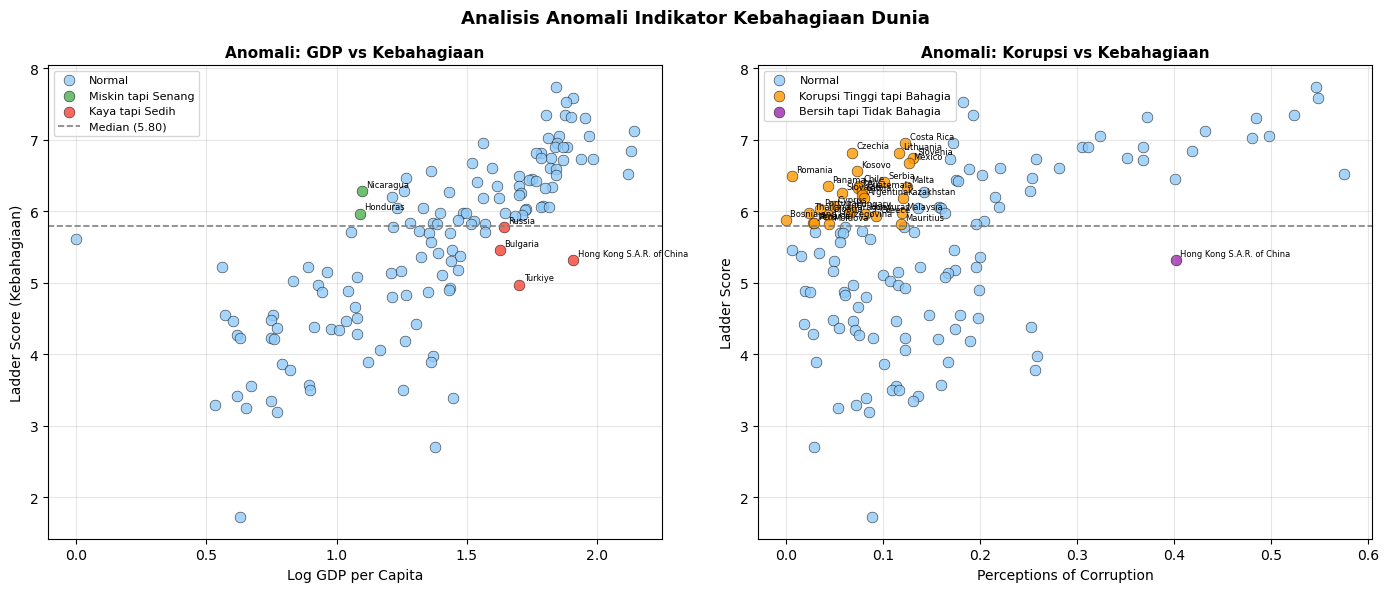

✅ Plot anomali disimpan


In [15]:
# Visualisasi Anomali — Scatter Plot Kuadran
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: GDP vs Ladder Score
ax = axes[0]
colors_map = {'Normal':'#90CAF9', 'Miskin tapi Senang':'#4CAF50', 'Kaya tapi Sedih':'#F44336'}
for tipe, color in colors_map.items():
    mask = df['Anomali_GDP'] == tipe
    ax.scatter(df.loc[mask, 'Log GDP per capita'], df.loc[mask, 'Ladder score'],
               c=color, label=tipe, alpha=0.8, s=60, edgecolors='k', linewidths=0.4)

ax.axhline(y=median_ladder, color='gray', linestyle='--', linewidth=1.2, label=f'Median ({median_ladder:.2f})')
# Annotasi negara anomali
for _, row in df[df['Anomali_GDP'] != 'Normal'].iterrows():
    ax.annotate(row['Country name'], (row['Log GDP per capita'], row['Ladder score']),
                fontsize=6, xytext=(3,3), textcoords='offset points')
ax.set_xlabel('Log GDP per Capita'); ax.set_ylabel('Ladder Score (Kebahagiaan)')
ax.set_title('Anomali: GDP vs Kebahagiaan', fontsize=11, fontweight='bold')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# Plot 2: Korupsi vs Ladder Score
ax2 = axes[1]
colors_map2 = {'Normal':'#90CAF9', 'Korupsi Tinggi tapi Bahagia':'#FF9800', 'Bersih tapi Tidak Bahagia':'#9C27B0'}
for tipe, color in colors_map2.items():
    mask = df['Anomali_Korupsi'] == tipe
    ax2.scatter(df.loc[mask, 'Perceptions of corruption'], df.loc[mask, 'Ladder score'],
                c=color, label=tipe, alpha=0.8, s=60, edgecolors='k', linewidths=0.4)
ax2.axhline(y=median_ladder, color='gray', linestyle='--', linewidth=1.2)
for _, row in df[df['Anomali_Korupsi'] != 'Normal'].iterrows():
    ax2.annotate(row['Country name'], (row['Perceptions of corruption'], row['Ladder score']),
                 fontsize=6, xytext=(3,3), textcoords='offset points')
ax2.set_xlabel('Perceptions of Corruption'); ax2.set_ylabel('Ladder Score')
ax2.set_title('Anomali: Korupsi vs Kebahagiaan', fontsize=11, fontweight='bold')
ax2.legend(fontsize=8); ax2.grid(True, alpha=0.3)

plt.suptitle('Analisis Anomali Indikator Kebahagiaan Dunia', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_anomali.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Plot anomali disimpan")

In [16]:
# Top 10 per Kategori Variabel (GMM Univariant)
print("=" * 30)
print("Hasil Analisis Variabel — GMM Univariant")
print("=" * 30)

# GDP
for kat in ['Miskin', 'Menengah', 'Kaya']:
    sub = df[df['GDP_Kategori'] == kat].sort_values('Log GDP per capita', ascending=(kat == 'Miskin')).head(10)
    print(f"\n[GDP] {kat} ({len(df[df['GDP_Kategori']==kat])} negara) — Top 10:")
    print(sub[['Country name', 'Log GDP per capita']].to_string(index=False))

# Sosial
for kat in ['Dukungan Sosial Rendah', 'Dukungan Sosial Sedang', 'Dukungan Sosial Tinggi']:
    sub = df[df['Sosial_Kategori'] == kat].sort_values('Social support', ascending=False).head(10)
    print(f"\n[Sosial] {kat} ({len(df[df['Sosial_Kategori']==kat])} negara) — Top 10:")
    print(sub[['Country name', 'Social support']].to_string(index=False))

# Harapan Hidup
for kat in ['Harapan Hidup Rendah', 'Harapan Hidup Sedang', 'Harapan Hidup Tinggi']:
    sub = df[df['Healthy_Kategori'] == kat].sort_values('Healthy life expectancy', ascending=False).head(10)
    print(f"\n[Healthy] {kat} ({len(df[df['Healthy_Kategori']==kat])} negara) — Top 10:")
    print(sub[['Country name', 'Healthy life expectancy']].to_string(index=False))

# Kebebasan
for kat in ['Kebebasan Rendah', 'Kebebasan Sedang', 'Kebebasan Tinggi']:
    sub = df[df['Freedom_Kategori'] == kat].sort_values('Freedom to make life choices', ascending=False).head(10)
    print(f"\n[Freedom] {kat} ({len(df[df['Freedom_Kategori']==kat])} negara) — Top 10:")
    print(sub[['Country name', 'Freedom to make life choices']].to_string(index=False))

# Generosity
for kat in ['Kurang Dermawan', 'Netral', 'Dermawan']:
    sub = df[df['Generosity_Kategori'] == kat].sort_values('Generosity', ascending=False).head(10)
    print(f"\n[Generosity] {kat} ({len(df[df['Generosity_Kategori']==kat])} negara) — Top 10:")
    print(sub[['Country name', 'Generosity']].to_string(index=False))

# Korupsi
for kat in ['Tinggi Korupsi', 'Korupsi Sedang', 'Rendah Korupsi']:
    sub = df[df['Corruption_Kategori'] == kat].sort_values('Perceptions of corruption', ascending=False).head(10)
    print(f"\n[Korupsi] {kat} ({len(df[df['Corruption_Kategori']==kat])} negara) — Top 10:")
    print(sub[['Country name', 'Perceptions of corruption']].to_string(index=False))

Hasil Analisis Variabel — GMM Univariant

[GDP] Miskin (40 negara) — Top 10:
    Country name  Log GDP per capita
       Venezuela               0.000
Congo (Kinshasa)               0.534
      Mozambique               0.560
           Niger               0.573
            Chad               0.603
          Malawi               0.617
         Liberia               0.619
      Madagascar               0.628
     Afghanistan               0.628
    Sierra Leone               0.654

[GDP] Menengah (49 negara) — Top 10:
      Country name  Log GDP per capita
        Montenegro               1.571
         Mauritius               1.570
         Argentina               1.562
        Costa Rica               1.561
            Serbia               1.538
             Libya               1.526
            Mexico               1.521
Dominican Republic               1.517
             China               1.497
          Thailand               1.484

[GDP] Kaya (51 negara) — Top 10:
             Co

In [17]:
# Simpan Hasil ke CSV (untuk Flask Backend)
output_cols = ['Country name', 'Ladder score',
               'Log GDP per capita', 'Social support', 'Healthy life expectancy',
               'Freedom to make life choices', 'Generosity', 'Perceptions of corruption',
               'Cluster_DBSCAN', 'Cluster_GMM', 'GMM_Prob_Max',
               'GDP_Kategori', 'Sosial_Kategori', 'Healthy_Kategori',
               'Freedom_Kategori', 'Generosity_Kategori', 'Corruption_Kategori',
               'Anomali_GDP', 'Anomali_Korupsi', 'Anomali_Generosity']

df[output_cols].to_csv('Hasil_Clustering_WHR2024.csv', index=False)
print("File 'Hasil_Clustering_WHR2024.csv' berhasil disimpan!")
print(f" Total negara: {len(df)}")
print(f" Total kolom output: {len(output_cols)}")
df[output_cols].head(5)

File 'Hasil_Clustering_WHR2024.csv' berhasil disimpan!
 Total negara: 140
 Total kolom output: 20


,Country name,Ladder score,Log GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Cluster_DBSCAN,Cluster_GMM,GMM_Prob_Max,GDP_Kategori,Sosial_Kategori,Healthy_Kategori,Freedom_Kategori,Generosity_Kategori,Corruption_Kategori,Anomali_GDP,Anomali_Korupsi,Anomali_Generosity
0,Finland,7.741,1.844,1.572,0.695,0.859,0.142,0.546,0,0,1.000000,Kaya,Dukungan Sosial Tinggi,Harapan Hidup Tinggi,Kebebasan Tinggi,Netral,Rendah Korupsi,Normal,Normal,Normal
1,Denmark,7.583,1.908,1.520,0.699,0.823,0.204,0.548,0,0,1.000000,Kaya,Dukungan Sosial Tinggi,Harapan Hidup Tinggi,Kebebasan Tinggi,Netral,Rendah Korupsi,Normal,Normal,Normal
2,Iceland,7.525,1.881,1.617,0.718,0.819,0.258,0.182,0,0,0.985193,Kaya,Dukungan Sosial Tinggi,Harapan Hidup Tinggi,Kebebasan Tinggi,Dermawan,Korupsi Sedang,Normal,Normal,Normal
3,Sweden,7.344,1.878,1.501,0.724,0.838,0.221,0.524,0,0,1.000000,Kaya,Dukungan Sosial Tinggi,Harapan Hidup Tinggi,Kebebasan Tinggi,Dermawan,Rendah Korupsi,Normal,Normal,Normal
4,Israel,7.341,1.803,1.513,0.740,0.641,0.153,0.193,0,0,0.997231,Kaya,Dukungan Sosial Tinggi,Harapan Hidup Tinggi,Kebebasan Sedang,Netral,Korupsi Sedang,Normal,Normal,Normal
